In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data1=pd.read_csv("/content/Cleaned_dataset.csv")

In [ ]:
data1.shape

(12575, 11)

In [ ]:
data1.dtypes

,0
Transaction ID,object
Customer ID,object
Category,object
Item,object
Price Per Unit,float64
Quantity,float64
Total Spent,float64
Payment Method,object
Location,object
Transaction Date,object


In [ ]:
data1.head(5)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize']=(10, 5)
print("Datasets are succesfully loaded, total records- ", len(data1))

Datasets are succesfully loaded, total records-  12575


/tmp/ipykernel_2045/2770933411.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_sales.values, y=category_sales.index, palette='viridis')


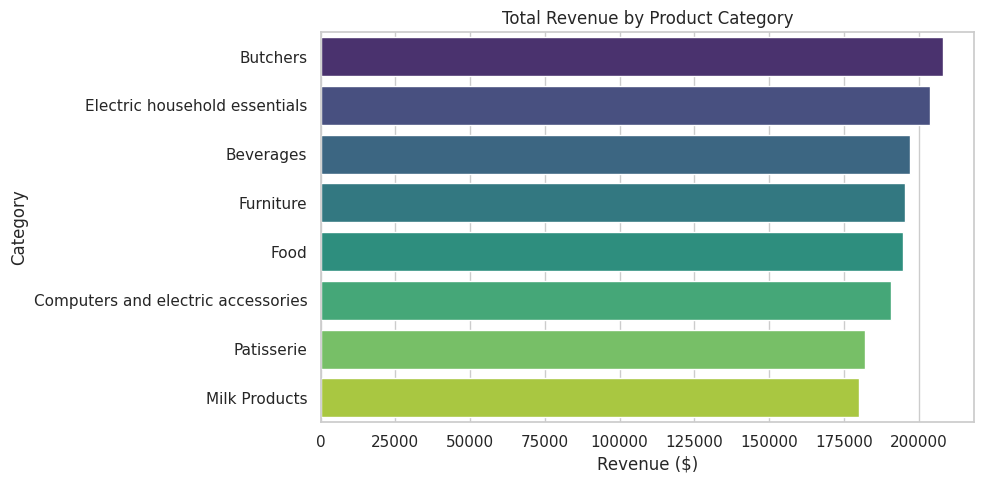

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
category_sales = data1.groupby('Category')['Total Spent'].sum().sort_values(ascending=False)
sns.barplot(x=category_sales.values, y=category_sales.index, palette='viridis')

plt.title('Total Revenue by Product Category')
plt.xlabel('Revenue ($)')
plt.ylabel('Category')
plt.tight_layout()
plt.savefig('../dashboards/category_revenue.png', dpi=300, bbox_inches='tight')

plt.show()

Identify top selling items: 
Top 10 Items: 


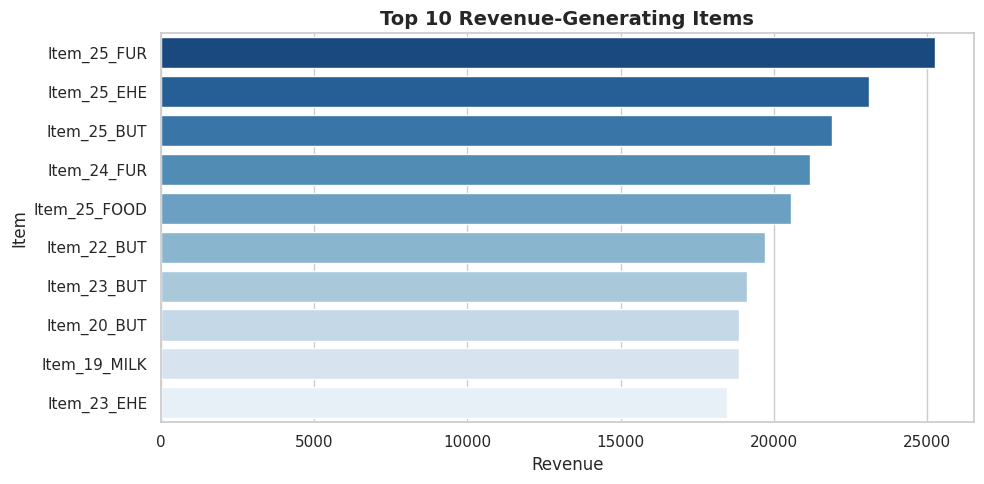

In [ ]:
print("Identify top selling items: ")
top_items = data1.groupby('Item')['Total Spent'].sum().nlargest(10).reset_index()

print("Top 10 Items: ")
plt.figure(figsize=(10, 5))
sns.barplot(data=top_items, x='Total Spent', y='Item', hue='Item', legend=False, palette='Blues_r')
plt.title('Top 10 Revenue-Generating Items', fontsize=14, fontweight='bold')
plt.xlabel('Revenue', fontsize=12)
plt.ylabel('Item', fontsize=12)
plt.tight_layout()
plt.savefig('../dashboards/top_items.png', dpi=300, bbox_inches='tight')
plt.show()

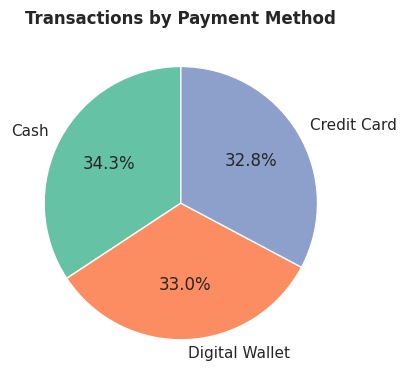

In [ ]:
plt.figure(figsize=(6, 4))
data1['Payment Method'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2')
)
plt.title('Transactions by Payment Method', fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../dashboards/payment_method_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

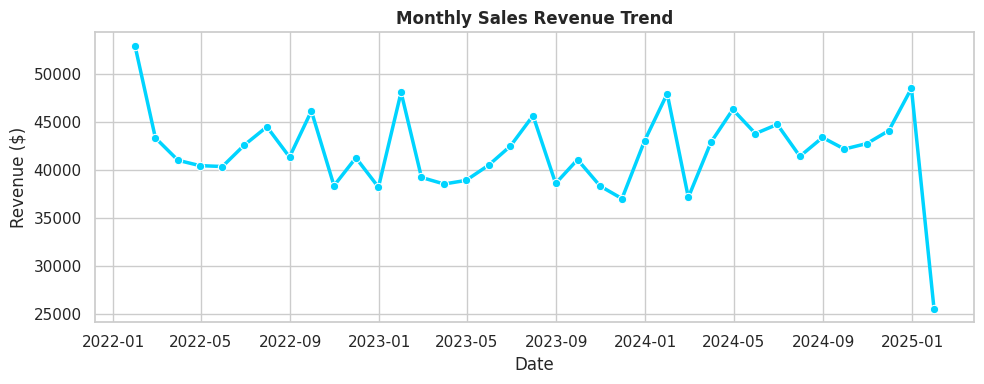

In [ ]:
data1['Transaction Date'] = pd.to_datetime(data1['Transaction Date'])
monthly_rev = data1.resample('ME', on='Transaction Date')['Total Spent'].sum().reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(data=monthly_rev, x='Transaction Date', y='Total Spent', marker='o', color='#00D4FF', linewidth=2.5)
plt.title('Monthly Sales Revenue Trend', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.tight_layout()
plt.savefig('../dashboards/monthly_revenue_trend.png', dpi=300, bbox_inches='tight')
plt.show()

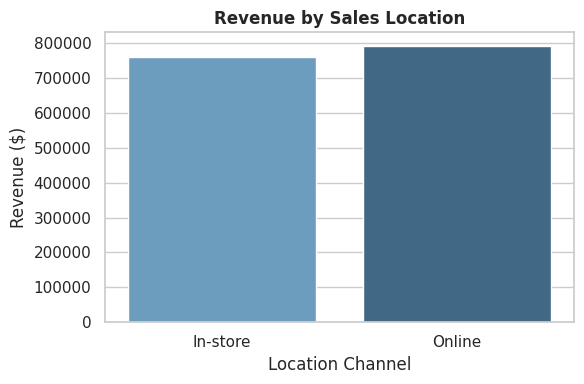

In [ ]:
plt.figure(figsize=(6, 4))
loc_rev = data1.groupby('Location')['Total Spent'].sum().reset_index()
sns.barplot(data=loc_rev, x='Location', y='Total Spent', hue='Location', legend=False, palette='Blues_d')
plt.title('Revenue by Sales Location', fontweight='bold')
plt.xlabel('Location Channel')
plt.ylabel('Revenue ($)')
plt.tight_layout()
plt.savefig('../dashboards/revenue_by_location.png', dpi=300, bbox_inches='tight')
plt.show()